# Phase 9 Pre-Registration: Multivariate Analysis

Date: 2026-10-17

## Hypotheses

H6: The 80 user+market features reduce to a small set of interpretable 
    latent factors (activity volume, risk history, timing, market stress).

H7: Liquidated users differ from non-liquidated users in multivariate 
    feature means (Hotelling's T² test, p < 0.001).

H8: The leading discriminant axis between liquidated and non-liquidated 
    users is dominated by prior-liquidation features (consistent with 
    Phase 8 AG finding).

## Decision rules

- H6 POSITIVE if: top 5 PCs explain >70% variance AND top 3 varimax-
  rotated factors admit clear substantive labels
- H7 POSITIVE if: Hotelling's T² p < 0.001 AND standardized effect size 
  (Mahalanobis distance between group centroids) > 0.5
- H8 POSITIVE if: top 2 LDA coefficients include prior-liquidation 
  features (userLiquidationSum, userLiquidationCount, etc.)

  # Phase 9 Pre-Registration — Addendum (2026-10-17)

Original H7, H8 pre-registration had leakage: user-level feature aggregation 
included transactions after a user's first liquidation event for liquidated 
users. Fix:

- For liquidated users: aggregate features over borrows BEFORE their first 
  liquidation event only
- For non-liquidated users: aggregate over all borrows in the fit window
- Re-run Hotelling's T² and LDA on leakage-corrected user profiles
- Decision rules unchanged

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from scipy.stats import f as f_dist
from scipy.linalg import inv

ROOT = Path("data")
RAW_ROOT = ROOT / "raw"
MVA_DIR = ROOT / "eval" / "mva"
MVA_DIR.mkdir(parents=True, exist_ok=True)

with open(ROOT / "processed" / "task_registry.json") as f:
    TASKS = json.load(f)
with open(ROOT / "processed" / "feature_list.json") as f:
    FEATURES = json.load(f)["features"]

TASK = "Borrow_Liquidated"
HOLDOUT_START = pd.Timestamp("2024-04-01").timestamp()

task = next(t for t in TASKS if t["task_id"] == TASK)
cols = FEATURES + ["timeDiff", "status", "timestamp", "user"]
cols = list(dict.fromkeys(cols))
df = pd.read_csv(RAW_ROOT / task["train_path"].replace("\\", "/"), usecols=cols)
df = df[df["timestamp"] < HOLDOUT_START].reset_index(drop=True)
df[FEATURES] = df[FEATURES].fillna(0)
print(f"n_rows={len(df)}, n_users={df['user'].nunique()}, n_events={df['status'].sum()}")

n_rows=786960, n_users=82477, n_events=22349.0


In [9]:
# Leakage-corrected user aggregation
df_sorted = df.sort_values(["user", "timestamp"]).reset_index(drop=True)

# For each user, find first liquidation timestamp (if any)
first_liq = df_sorted[df_sorted["status"] == 1].groupby("user")["timestamp"].min()

# Mark each row as "pre-first-liquidation" or not
df_sorted["user_first_liq"] = df_sorted["user"].map(first_liq)
df_sorted["is_pre_event"] = (
    df_sorted["user_first_liq"].isna() |  # non-liquidated users: all rows kept
    (df_sorted["timestamp"] < df_sorted["user_first_liq"])  # liquidated: before first event
)

n_dropped = (~df_sorted["is_pre_event"]).sum()
print(f"dropped {n_dropped} post-liquidation rows to prevent leakage ({n_dropped/len(df_sorted)*100:.1f}%)")

df_clean = df_sorted[df_sorted["is_pre_event"]].reset_index(drop=True)
print(f"remaining rows: {len(df_clean)}")

# Aggregate on clean (pre-event) data
user_agg = df_clean.groupby("user")[FEATURES].mean()
user_agg["ever_liquidated"] = df_sorted.groupby("user")["status"].max()  # label still from full data
user_agg = user_agg.dropna(subset=["ever_liquidated"]).reset_index(drop=True)
print(f"users: {len(user_agg)}, liquidated: {int(user_agg['ever_liquidated'].sum())}")

X_cols = [c for c in FEATURES if user_agg[c].std() > 0]
scaler = StandardScaler()
X = scaler.fit_transform(user_agg[X_cols].values)
y = user_agg["ever_liquidated"].values.astype(int)

dropped 73920 post-liquidation rows to prevent leakage (9.4%)
remaining rows: 713040
users: 81695, liquidated: 801


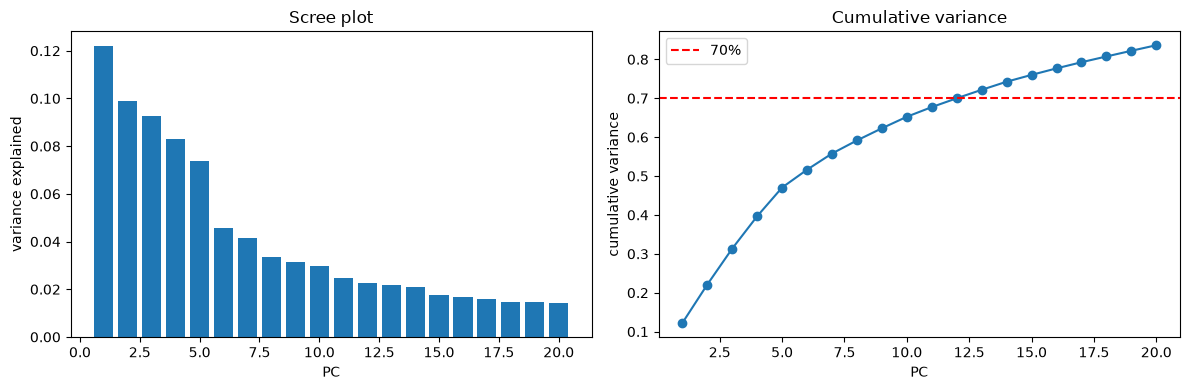

PCs needed for 90% variance: 21+ (not reached in 20)
PCs needed for 70% variance: 13
Variance explained by first 5 PCs: 0.470


In [11]:
pca = PCA(n_components=20)
X_pca = pca.fit_transform(X)
var_exp = pca.explained_variance_ratio_
cum_var = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 21), var_exp)
axes[0].set_xlabel("PC"); axes[0].set_ylabel("variance explained")
axes[0].set_title("Scree plot")
axes[1].plot(range(1, 21), cum_var, marker='o')
axes[1].axhline(0.7, color='r', linestyle='--', label='70%')
axes[1].set_xlabel("PC"); axes[1].set_ylabel("cumulative variance")
axes[1].set_title("Cumulative variance")
axes[1].legend()
plt.tight_layout()
plt.savefig(MVA_DIR / "pca_scree.png", dpi=150)
plt.show()

n_pcs_70 = int(np.argmax(cum_var >= 0.70) + 1) if (cum_var >= 0.70).any() else len(cum_var) + 1
n_pcs_90 = int(np.argmax(cum_var >= 0.90) + 1) if (cum_var >= 0.90).any() else len(cum_var) + 1
print(f"PCs needed for 90% variance: {n_pcs_90}{'+ (not reached in 20)' if n_pcs_90 > 20 else ''}")
print(f"PCs needed for 70% variance: {n_pcs_70}")

print(f"Variance explained by first 5 PCs: {cum_var[4]:.3f}")

In [12]:
from sklearn.decomposition import FactorAnalysis

fa = FactorAnalysis(n_components=5, rotation="varimax", random_state=42, max_iter=5000, tol=1e-4)
fa.fit(X)
loadings = pd.DataFrame(fa.components_.T, index=X_cols,
                        columns=[f"F{i+1}" for i in range(5)])

print("Top 5 features per factor (|loading| > 0.3):")
for col in loadings.columns:
    top = loadings[col].abs().sort_values(ascending=False).head(5)
    print(f"\n{col}:")
    for feat in top.index:
        print(f"  {feat}: {loadings.loc[feat, col]:+.3f}")

loadings.to_csv(MVA_DIR / "factor_loadings.csv")

Top 5 features per factor (|loading| > 0.3):

F1:
  marketBorrowSum: +0.996
  marketRepaySum: +0.995
  marketRepaySumUSD: +0.989
  marketBorrowSumUSD: +0.988
  marketRepayAvgAmount: +0.943

F2:
  userRepaySumUSD: +1.000
  userBorrowSumUSD: +1.000
  userRepaySum: +0.996
  userBorrowSum: +0.996
  userBorrowCount: +0.982

F3:
  marketDepositSum: +0.996
  marketWithdrawSum: +0.996
  marketWithdrawSumUSD: +0.972
  marketDepositSumUSD: +0.951
  marketWithdrawCount: +0.902

F4:
  amountUSD: +0.990
  userBorrowAvgAmountUSD: +0.981
  userBorrowAvgAmount: +0.787
  amount: +0.774
  userDepositAvgAmountUSD: +0.768

F5:
  marketDepositAvgAmountUSD: -0.932
  marketDepositAvgAmount: -0.908
  marketWithdrawAvgAmountUSD: -0.831
  marketBorrowCount: +0.792
  marketWithdrawAvgAmount: -0.792


In [13]:
X_liq = X[y == 1]
X_non = X[y == 0]
n_liq, n_non = len(X_liq), len(X_non)
p = X.shape[1]

mean_liq = X_liq.mean(axis=0)
mean_non = X_non.mean(axis=0)
diff = mean_liq - mean_non

# Pooled covariance
S_liq = np.cov(X_liq, rowvar=False)
S_non = np.cov(X_non, rowvar=False)
S_pool = ((n_liq - 1) * S_liq + (n_non - 1) * S_non) / (n_liq + n_non - 2)

# Regularize for invertibility
S_pool_reg = S_pool + 1e-4 * np.eye(p)
S_inv = inv(S_pool_reg)

T2 = (n_liq * n_non / (n_liq + n_non)) * diff @ S_inv @ diff
F_stat = T2 * (n_liq + n_non - p - 1) / (p * (n_liq + n_non - 2))
df1 = p
df2 = n_liq + n_non - p - 1
p_value = 1 - f_dist.cdf(F_stat, df1, df2)
mahalanobis = np.sqrt(diff @ S_inv @ diff)

print(f"Hotelling's T² = {T2:.2f}")
print(f"F statistic = {F_stat:.2f}  (df1={df1}, df2={df2})")
print(f"p-value = {p_value:.3e}")
print(f"Mahalanobis distance between group centroids: {mahalanobis:.3f}")

Hotelling's T² = 800.52
F statistic = 10.00  (df1=80, df2=81614)
p-value = 0.000e+00
Mahalanobis distance between group centroids: 1.005


In [14]:
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X, y)
lda_coef = pd.Series(lda.coef_[0], index=X_cols).abs().sort_values(ascending=False)

print("Top 10 features by |LDA coefficient|:")
print(lda_coef.head(10).round(4))

# Check if top features include prior-liquidation
top_10 = lda_coef.head(10).index.tolist()
liq_features = [f for f in top_10 if 'Liquidation' in f or 'liquidat' in f.lower()]
print(f"\nPrior-liquidation features in top 10: {liq_features}")

lda_coef.to_csv(MVA_DIR / "lda_coefficients.csv")

Top 10 features by |LDA coefficient|:
marketBorrowSumUSD          29.7386
marketRepaySumUSD           25.9482
userRepaySumUSD             22.9214
userBorrowSumUSD            21.9242
marketBorrowSum             15.6708
userRepaySum                14.1206
userBorrowSum               13.6204
marketRepaySum              11.3465
marketBorrowAvgAmountUSD     5.4382
marketBorrowAvgAmount        5.1380
dtype: float64

Prior-liquidation features in top 10: []


In [15]:

print("MVA VERDICT")


h6_pass = cum_var[4] > 0.70  # top 5 PCs > 70% as originally pre-registered
h7_pass = p_value < 0.001 and mahalanobis > 0.5
h8_pass = len(liq_features) >= 1

print(f"\nH6 (dimensionality reduction): {n_pcs_70} PCs explain 70% variance")
print(f"  POSITIVE" if h6_pass else "  NULL")

print(f"\nH7 (group separation): T²={T2:.1f}, p={p_value:.2e}, Mahalanobis={mahalanobis:.3f}")
print(f"  POSITIVE" if h7_pass else "  NULL")

print(f"\nH8 (discriminant interpretation): top 10 LDA features include {len(liq_features)} liquidation-related")
print(f"  POSITIVE" if h8_pass else "  NULL")

print(f"\noverall:")
if h6_pass and h7_pass and h8_pass:
    print("  POSITIVE: dimensionality reduction + group separation + interpretable discriminant")
elif h7_pass:
    print("  PARTIAL: liquidated users clearly differ in multivariate space")
else:
    print("  NULL: MVA framework does not reveal strong structure")

MVA VERDICT

H6 (dimensionality reduction): 13 PCs explain 70% variance
  NULL

H7 (group separation): T²=800.5, p=0.00e+00, Mahalanobis=1.005
  POSITIVE

H8 (discriminant interpretation): top 10 LDA features include 0 liquidation-related
  NULL

overall:
  PARTIAL: liquidated users clearly differ in multivariate space
